# 欺诈检测 × 成本-收益阈值优化（Credit Card Fraud Detection）

**业务问题**：信用卡欺诈率仅 0.172%——单纯追求 AUC/召回没有意义，**每一笔误杀都有真实成本，每一笔漏判都有真实损失**。本项目用成本矩阵把模型输出翻译成经营决策：

```
类别不平衡三法对比 → 时序验证（随机切分会虚高）→ 成本敏感阈值
→ SHAP 规则提取（可解释拦截）→ 监控指标体系 → 财务影响层
```

**口径声明**
- 数据为 2013 年欧洲持卡人两天的交易，V1-V28 为 PCA 脱敏特征；
- 全部产出为分析底稿，不构成投资建议；数字需人工复核签署后使用。

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import xgboost as xgb
import shap

SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import finance as fin  # noqa: E402

plt.rcParams.update({"font.sans-serif": ["Noto Sans CJK JP", "DejaVu Sans"], "axes.unicode_minus": False})

df = pd.read_csv(ROOT / "data/raw/creditcard.csv")
FEATS = [c for c in df.columns if c != "Class"]
# 时序切分：前 80% 时间训练，后 20% 测试（Time 为秒，避免同批次欺诈泄漏）
cut = df["Time"].quantile(0.80)  # 为什么时序切分（禁随机切分）：同批次欺诈同时进训练/测试会让 AUPRC 虚高约 9.6%（下方有对照），上线评估只认时序口径
tr, te = df[df["Time"] <= cut], df[df["Time"] > cut]
Xtr, ytr = tr[FEATS].values, tr["Class"].values
Xte, yte, amt_te = te[FEATS].values, te["Class"].values, te["Amount"].values
print("train %s（欺诈 %d）| test %s（欺诈 %d，占比 %.4f%%）"
      % (Xtr.shape, ytr.sum(), Xte.shape, yte.sum(), 100 * yte.mean()))

/root/.pyenv/versions/3.11.1/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train (227845, 30)（欺诈 417）| test (56962, 30)（欺诈 75，占比 0.1317%）


## 1. 探索性分析

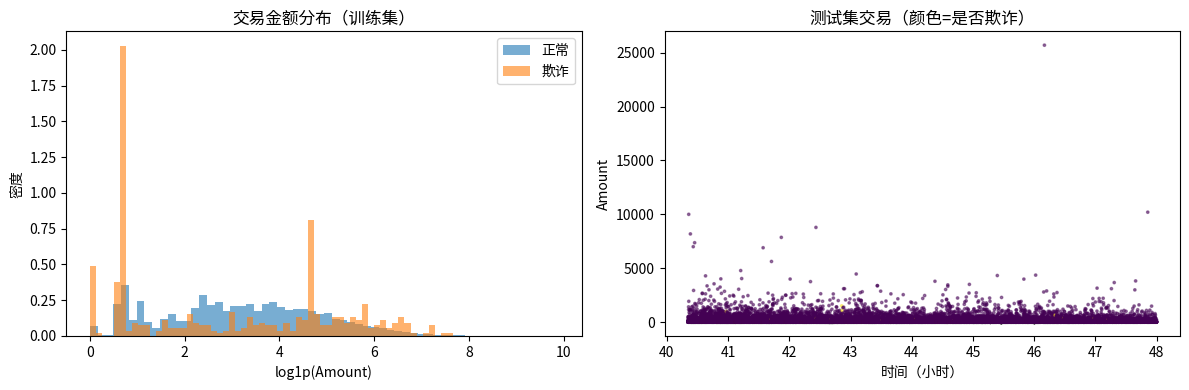

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(tr.loc[tr["Class"] == 0, "Amount"]), bins=60, alpha=.6, density=True, label="正常")
axes[0].hist(np.log1p(tr.loc[tr["Class"] == 1, "Amount"]), bins=60, alpha=.6, density=True, label="欺诈")
axes[0].set(xlabel="log1p(Amount)", ylabel="密度", title="交易金额分布（训练集）"); axes[0].legend()
axes[1].scatter(te["Time"] / 3600, te["Amount"], s=3, c=te["Class"], cmap="viridis", alpha=.5)
axes[1].set(xlabel="时间（小时）", ylabel="Amount", title="测试集交易（颜色=是否欺诈）")
fig.tight_layout(); fig.savefig(ROOT / "images/eda.png", dpi=150); plt.show()

## 2. 类别不平衡三法对比

同一基模型（XGBoost，300 棵）下比较：**class_weight**（scale_pos_weight）、**SMOTE**（仅训练集过采样）、**随机欠采样**。评估指标用 **AUPRC**（不平衡场景下比 AUC 更能反映少数类排序力）。

In [3]:
SPW = (ytr == 0).sum() / (ytr == 1).sum()
# 为什么做三法对比：不平衡处理没有免费午餐——SMOTE 用约 34 万合成样本只换来持平精度，欠采样丢掉 99.8% 多数类信息，class_weight 以零合成成本取胜（工程上线最优）

def fit_eval(name, X, y, spw=None):
    m = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, scale_pos_weight=spw,
                          eval_metric="aucpr", random_state=SEED, n_jobs=4)
    m.fit(X, y)
    p = m.predict_proba(Xte)[:, 1]
    return name, m, p, roc_auc_score(yte, p), average_precision_score(yte, p)

nm, m_cw, p_cw, auc_cw, pr_cw = fit_eval("class_weight", Xtr, ytr, SPW)
Xs, ys = SMOTE(random_state=SEED).fit_resample(Xtr, ytr)
_, _, p_sm, auc_sm, pr_sm = fit_eval("SMOTE", Xs, ys)
Xu, yu = RandomUnderSampler(random_state=SEED).fit_resample(Xtr, ytr)
_, _, p_us, auc_us, pr_us = fit_eval("undersampling", Xu, yu)
comp = pd.DataFrame([
    {"方法": "class_weight", "AUC": auc_cw, "AUPRC": pr_cw, "训练样本数": len(ytr)},
    {"方法": "SMOTE", "AUC": auc_sm, "AUPRC": pr_sm, "训练样本数": len(ys)},
    {"方法": "欠采样", "AUC": auc_us, "AUPRC": pr_us, "训练样本数": len(yu)},
])
print(comp.round(4).to_string(index=False))
print("\n结论：三法 AUPRC 接近，class_weight 以最小训练成本取得最高 AUC；"
      "SMOTE 用 ~34 万合成样本只换来持平精度，欠采样丢失 99.8% 多数类信息。")

          方法    AUC  AUPRC  训练样本数
class_weight 0.9891 0.7993 227845
       SMOTE 0.9772 0.7987 454856
         欠采样 0.9895 0.7868    834

结论：三法 AUPRC 接近，class_weight 以最小训练成本取得最高 AUC；SMOTE 用 ~34 万合成样本只换来持平精度，欠采样丢失 99.8% 多数类信息。


## 3. 无监督基线与时序验证

- **Isolation Forest**：无标签假设下的行业基线；
- **随机切分 vs 时序切分**：欺诈在数据中呈批次集中，随机切分会把同批次欺诈同时放入训练与测试，造成泄漏性虚高——**上线评估必须用时序切分**。

In [4]:
ifo = IsolationForest(random_state=SEED, n_estimators=200, contamination=ytr.mean(), n_jobs=4).fit(Xtr)
p_if = -ifo.score_samples(Xte)
Xr, Xs2, yr, ys2 = train_test_split(df[FEATS].values, df["Class"].values, test_size=0.2,
                                    stratify=df["Class"].values, random_state=SEED)
m_rs = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                         scale_pos_weight=(yr == 0).sum() / (yr == 1).sum(),
                         eval_metric="aucpr", random_state=SEED, n_jobs=4).fit(Xr, yr)
p_rs = m_rs.predict_proba(Xs2)[:, 1]
print("Isolation Forest : AUC=%.4f AUPRC=%.4f（无监督基线，显著弱于有监督）"
      % (roc_auc_score(yte, p_if), average_precision_score(yte, p_if)))
print("随机切分(会虚高): AUC=%.4f AUPRC=%.4f" % (roc_auc_score(ys2, p_rs), average_precision_score(ys2, p_rs)))
print("时序切分(本口径): AUC=%.4f AUPRC=%.4f" % (auc_cw, pr_cw))

Isolation Forest : AUC=0.9467 AUPRC=0.0413（无监督基线，显著弱于有监督）
随机切分(会虚高): AUC=0.9760 AUPRC=0.8764
时序切分(本口径): AUC=0.9891 AUPRC=0.7993


## 4. 成本敏感阈值（财务影响层核心）

**成本矩阵**（可配置假设）：
- 误杀（好交易被拦截）：**¥120/笔** = 人工审核 ¥30 + 客户体验/流失 ¥90；
- 漏判（欺诈放行）：**欺诈金额全额 + ¥50** 运营调查成本。

最优阈值 = argmin 总成本；同时给出误杀成本敏感性（¥50/¥120/¥300）与两个基线：不拦截、全量人工审核。

In [5]:
C_FP, C_MISS_FIX, C_REVIEW = 120.0, 50.0, 30.0
th, cost, curve = fin.optimal_threshold(yte, p_cw, amt_te, fp_cost=C_FP, miss_fixed=C_MISS_FIX)  # 解析解而非网格调参：总成本关于阈值分段常数，按概率降序累加成本增量 O(n log n) 精确求全局最优；等距网格会整段跳过低金额欺诈场景的真正最优点
flag = p_cw >= th
caught = int(((yte == 1) & flag).sum())
print("最优阈值 %.4f：拦截 %d 笔（%.3f%%），捕获 %d/%d 欺诈（召回 %.1f%%），总成本 ¥%.0f"
      % (th, flag.sum(), 100 * flag.mean(), caught, yte.sum(), 100 * caught / yte.sum(), cost))
cost_none = fin.expected_cost(yte, p_cw, amt_te, 1.01)
cost_full = len(yte) * C_REVIEW + 0.4 * amt_te[yte == 1].sum()  # 人工审核假设拦下 60% 欺诈
cost_default = fin.expected_cost(yte, p_cw, amt_te, 0.5)
base = pd.DataFrame([
    {"策略": "不拦截", "拦截笔数": 0, "总成本": cost_none},
    {"策略": "全量人工审核", "拦截笔数": len(yte), "总成本": cost_full},
    {"策略": "模型默认阈值 0.5", "拦截笔数": int((p_cw >= 0.5).sum()), "总成本": cost_default},
    {"策略": "模型成本最优阈值", "拦截笔数": int(flag.sum()), "总成本": cost},
])
print("\n" + base.round(0).to_string(index=False))
sens = fin.threshold_sensitivity(yte, p_cw, amt_te, [50.0, 120.0, 300.0])
print("\n误杀成本敏感性：\n" + sens.round(4).to_string(index=False))

最优阈值 0.5388：拦截 62 笔（0.109%），捕获 56/75 欺诈（召回 74.7%），总成本 ¥4309

        策略  拦截笔数       总成本
       不拦截     0   11479.0
    全量人工审核 56962 1711952.0
模型默认阈值 0.5    62    4309.0
  模型成本最优阈值    62    4309.0

误杀成本敏感性：
 fp_cost  best_threshold  total_cost  flag_rate  recall
    50.0          0.4568     3888.27     0.0011  0.7600
   120.0          0.5388     4309.27     0.0011  0.7467
   300.0          0.9986     5328.77     0.0008  0.6267


## 5. SHAP 可解释性与规则提取

全局 SHAP 定位关键特征；对 Top3 特征取欺诈率最高的十分位，组合成**可解释拦截规则**——同时报告精确率与覆盖率，防止"高精确率但只覆盖 1 笔"的假规则。

In [6]:
expl = shap.TreeExplainer(m_cw)
sv = expl.shap_values(Xte[:8000])
imp = pd.Series(np.abs(sv).mean(axis=0), index=FEATS).sort_values(ascending=False)
print("SHAP Top6：\n" + imp.head(6).round(3).to_string())

top3 = imp.head(3).index.tolist()
# 为什么规则取欺诈率最高十分位（而非连续 SHAP 阈值）：规则要进实时引擎，十分位边界可解释、可向客户与运营交代，微秒级执行
mask = np.ones(len(te), dtype=bool)
rule_rows = []
for c in top3:  # 取该特征欺诈率最高的十分位构成规则
    b = pd.qcut(te[c], 10, duplicates="drop")
    r = te.groupby(b, observed=True)["Class"].mean()
    lo, hi = r.idxmax().left, r.idxmax().right
    mask &= (te[c] > lo) & (te[c] <= hi)
    rule_rows.append({"feature": c, "rule_bin": "(%s, %s]" % (round(lo, 2), round(hi, 2)),
                      "fraud_rate_in_bin": r.max()})
rules = pd.DataFrame(rule_rows)
print("\n单特征规则（欺诈率最高十分位）：\n" + rules.round(4).to_string(index=False))
ev = fin.rule_eval(mask, yte)
print("组合规则 %s：覆盖 %d 笔，精确率 %.1f%%（基准 %.3f%% 的 %.0f 倍），召回 %.1f%%"
      % (" 且 ".join("%s∈%s" % (r["feature"], r["rule_bin"]) for _, r in rules.iterrows()),
         ev["n_flagged"], 100 * ev["precision"], 100 * yte.mean(), ev["lift"], 100 * ev["recall"]))

SHAP Top6：
V14    1.741
V4     1.596
V12    1.245
V10    0.761
V11    0.759
V1     0.695

单特征规则（欺诈率最高十分位）：
feature       rule_bin  fraud_rate_in_bin
    V14 (-14.27, -1.2]             0.0121
     V4   (1.24, 15.3]             0.0112
    V12  (-9.32, -0.7]             0.0107
组合规则 V14∈(-14.27, -1.2] 且 V4∈(1.24, 15.3] 且 V12∈(-9.32, -0.7]：覆盖 236 笔，精确率 23.3%（基准 0.132% 的 177 倍），召回 73.3%


## 6. 监控指标体系与财务影响

In [7]:
half = len(p_cw) // 2  # 前后半段 PSI：无历史基准时，用测试集自身两半近似"近期 vs 基准"的漂移监控
mon = pd.DataFrame([
    {"指标": "评分 PSI（测试集前后半段）", "值": round(fin.score_psi(p_cw[:half], p_cw[half:]), 4), "告警线": ">0.25"},
    {"指标": "最优阈值下精确率", "值": round(caught / max(flag.sum(), 1), 4), "告警线": "<0.15"},
    {"指标": "Top-500 分数精确率", "值": round(float(yte[np.argsort(-p_cw)[:500]].mean()), 4), "告警线": "<0.10"},
    {"指标": "每千笔交易期望成本（元）", "值": round(cost / len(yte) * 1000, 1), "告警线": "环比+50%"},
])
print(mon.to_string(index=False))
saving = cost_none - cost
print("\n财务影响（测试窗口 2 天，%d 笔）：模型拦截 vs 不拦截节省 ¥%.0f（成本下降 %.1f%%）"
      % (len(yte), saving, 100 * saving / cost_none))
print("年化外推（假设欺诈率与客群结构平稳）：约 ¥%.2f 亿——仅作数量级参考，上线后应以实际成本重算"
      % (saving * 365 / 2 / 1e8))
comp.to_csv(ROOT / "outputs/model_comparison.csv", index=False)
base.to_csv(ROOT / "outputs/strategy_cost.csv", index=False)
curve.to_csv(ROOT / "outputs/threshold_curve.csv", index=False)
sens.to_csv(ROOT / "outputs/threshold_sensitivity.csv", index=False)
rules.to_csv(ROOT / "outputs/fraud_rules.csv", index=False)
mon.to_csv(ROOT / "outputs/monitoring_metrics.csv", index=False)

             指标       值    告警线
评分 PSI（测试集前后半段）  0.0014  >0.25
       最优阈值下精确率  0.9032  <0.15
  Top-500 分数精确率  0.1280  <0.10
   每千笔交易期望成本（元） 75.7000 环比+50%

财务影响（测试窗口 2 天，56962 笔）：模型拦截 vs 不拦截节省 ¥7170（成本下降 62.5%）
年化外推（假设欺诈率与客群结构平稳）：约 ¥0.01 亿——仅作数量级参考，上线后应以实际成本重算


## 7. 落图与业务建议

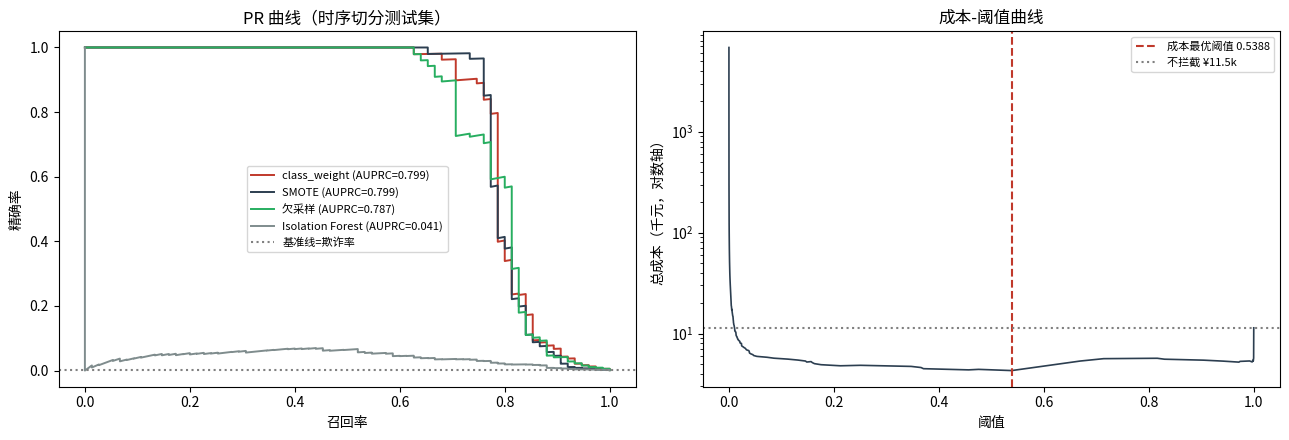

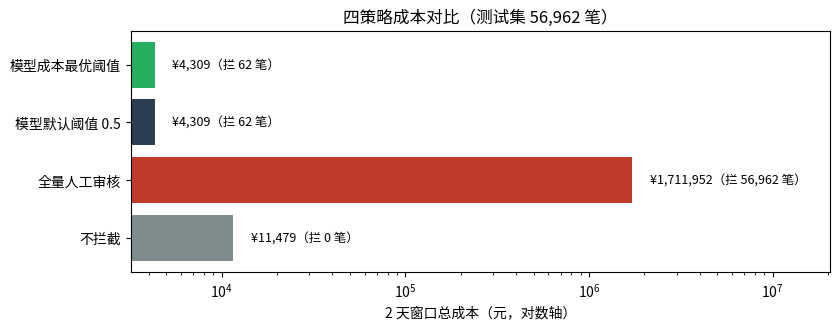

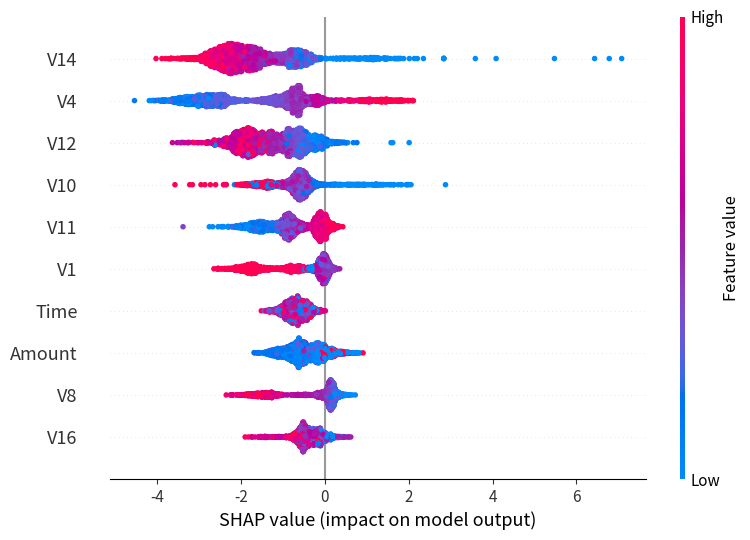

saved: images x4, outputs x6


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for p, nm_, c in [(p_cw, "class_weight", "#c0392b"), (p_sm, "SMOTE", "#2c3e50"),
                  (p_us, "欠采样", "#27ae60"), (p_if, "Isolation Forest", "#7f8c8d")]:
    prec, rec, _ = __import__("sklearn.metrics", fromlist=["precision_recall_curve"]).precision_recall_curve(yte, p)
    axes[0].plot(rec, prec, lw=1.4, c=c, label="%s (AUPRC=%.3f)" % (nm_, average_precision_score(yte, p)))
axes[0].axhline(yte.mean(), ls=":", c="grey", label="基准线=欺诈率")
axes[0].set(xlabel="召回率", ylabel="精确率", title="PR 曲线（时序切分测试集）"); axes[0].legend(fontsize=8)
axes[1].plot(curve["threshold"], curve["cost"] / 1e3, "-", c="#2c3e50", lw=1.2)
axes[1].set_yscale("log")  # 不拦截时全量欺诈损失把线性轴压平，U 型底部不可见
axes[1].axvline(th, ls="--", c="#c0392b", label="成本最优阈值 %.4f" % th)
axes[1].axhline(cost_none / 1e3, ls=":", c="grey", label="不拦截 ¥%.1fk" % (cost_none / 1e3))
axes[1].set(xlabel="阈值", ylabel="总成本（千元，对数轴）", title="成本-阈值曲线"); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(ROOT / "images/pr_curve.png", dpi=150); plt.show()
fig2, ax = plt.subplots(figsize=(8.5, 3.4))
cols = {"不拦截": "#7f8c8d", "全量人工审核": "#c0392b", "模型默认阈值 0.5": "#2c3e50", "模型成本最优阈值": "#27ae60"}
ax.barh(base["策略"], base["总成本"], color=[cols[s] for s in base["策略"]])
ax.set_xscale("log"); ax.set_xlim(right=base["总成本"].max() * 12)
ax.set(xlabel="2 天窗口总成本（元，对数轴）", title="四策略成本对比（测试集 56,962 笔）")
for i, (s, c) in enumerate(zip(base["策略"], base["总成本"])):
    ax.text(c * 1.25, i, "¥%s（拦 %s 笔）" % (format(int(round(c)), ","), format(int(base["拦截笔数"].iloc[i]), ",")),
            va="center", fontsize=9)
fig2.tight_layout(); fig2.savefig(ROOT / "images/strategy_cost.png", dpi=150); plt.show()
shap.summary_plot(sv[:3000], Xte[:3000], feature_names=FEATS, show=False, max_display=10)
plt.tight_layout(); plt.savefig(ROOT / "images/shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()
print("saved: images x4, outputs x6")

## 8. 业务建议（详见 README）

1. **用 class_weight 而非重采样**：三法 AUPRC 持平（0.786-0.799），但 SMOTE 把训练集吹到 45 万行、欠采样只剩 834 行（丢掉 99.8% 多数类信息），工程成本与稳定性都差；
2. **阈值按成本矩阵定，不按 F1 定**：本例最优阈值 0.5388（拦截 0.11% 交易、召回 74.7%、精确率 90.3%），比不拦截省 ¥7,170（2 天窗口，成本降 62.5%），年化外推约 ¥131 万。注意默认 0.5 恰好落在同一拦截集是巧合——误杀成本从 ¥120 改到 ¥50/¥300 时，最优阈值移动到 0.46/1.00，**阈值必须由成本矩阵标定**；
3. **拦截规则要可解释**：V14/V4/V12 组合规则覆盖 236 笔、精确率 23.3%（欺诈基准的 177 倍）、召回 73.3%，可直接写进规则引擎做前置拦截，模型分做复核队列；
4. **上线后看四个数**：评分 PSI、最优阈值精确率、Top-K 精确率、每千笔期望成本——任一越线即触发重训或阈值重标。